In [1]:
import numpy as np
import pandas as pd
from nltk.classify import NaiveBayesClassifier
from nltk.corpus import subjectivity
from nltk.sentiment import SentimentAnalyzer
from nltk.sentiment.util import *

import numpy as np 
import pandas as pd 
#pd.set_option('display.max_colwidth', -1)
from time import time
import re
import string
import os
from pprint import pprint
import collections

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid")
sns.set(font_scale=1.3)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import classification_report

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
#from sklearn.externals import joblib
import joblib as jb

#import gensim

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import warnings
warnings.filterwarnings('ignore')

np.random.seed(37)

In [2]:
# Reading the saved data pickle file
df  = pd.DataFrame()
df = pd.read_pickle('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/pickled_filtered_lead_para_sp500_clean.pkl', compression=None)
df_sentiment=pd.read_pickle('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/sentiment.pkl', compression=None)

In [3]:
df["articles"].describe()
df = df.join(df_sentiment)
df["vix"] = df["adj close"]
vix_yesterday = df["vix"].shift(periods=1)
df["vix_ln_return"]=np.log(df["vix"]/vix_yesterday)
df['sentiment'] = df[["sentiment"]].apply(pd.to_numeric)
df["sentiment_ewm"]=df["sentiment"].ewm(10).mean()
df["date"]=df.index
df_part1 = df.loc['2019-09-25':'2020-02-14']
df_part2 = df.loc['2020-02-15':'2020-05-31']
df_part3 = df.loc['2020-06-01':'2021-07-15']

<AxesSubplot:title={'center':'vix ln return'}>

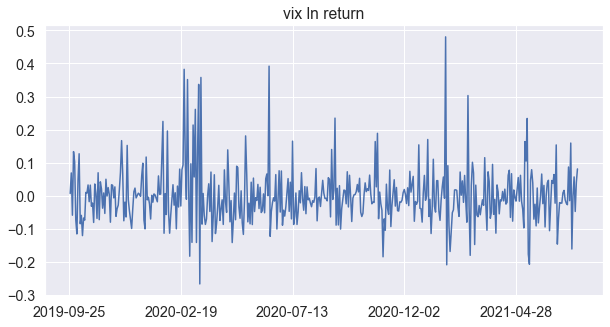

In [4]:
df["vix_ln_return"].plot(figsize=(10, 5),title='vix ln return')

<AxesSubplot:title={'center':'vix ln return'}>

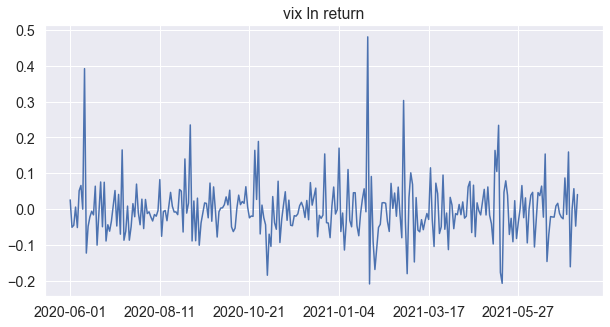

In [5]:
df_part3["vix_ln_return"].plot(figsize=(10, 5),title='vix ln return')

In [6]:
df1_part3 = df_part3
idx = pd.date_range('2020-06-01', '2021-07-15')
df1_part3.index = pd.DatetimeIndex(df1_part3.index)

In [7]:
import datetime as dt
from datetime import date
import calendar
my_date = date.today()
calendar.day_name[my_date.weekday()]  #'Wednesday'

# Prepare data
df_part3['year'] = [d.year for d in df_part3.index]
df_part3['month'] = [d.strftime('%b') for d in df_part3.index]
df_part3['day'] = [d for d in df_part3.index.day_name()]
years = df_part3['year'].unique()
df_part3['month-year'] = [d.strftime('%b') + str(d.year) for d in df_part3.index]


In [8]:
# Split data into train data(including validation data) and test data
split_ratio = 0.8

data = df_part3.set_index('day')
len_data = df_part3.shape[0]

train_org = df_part3.iloc[:int(len_data*split_ratio),]
test_org = df_part3.iloc[int(len_data*split_ratio):,]

print('train set',train_org.shape)
print('test set',test_org.shape)

train set (227, 17)
test set (57, 17)


In [9]:
df['Num_word'] = df['articles'].apply(lambda x:len(str(x).split())) #Number Of words in main text

<AxesSubplot:title={'center':'Number of words'}>

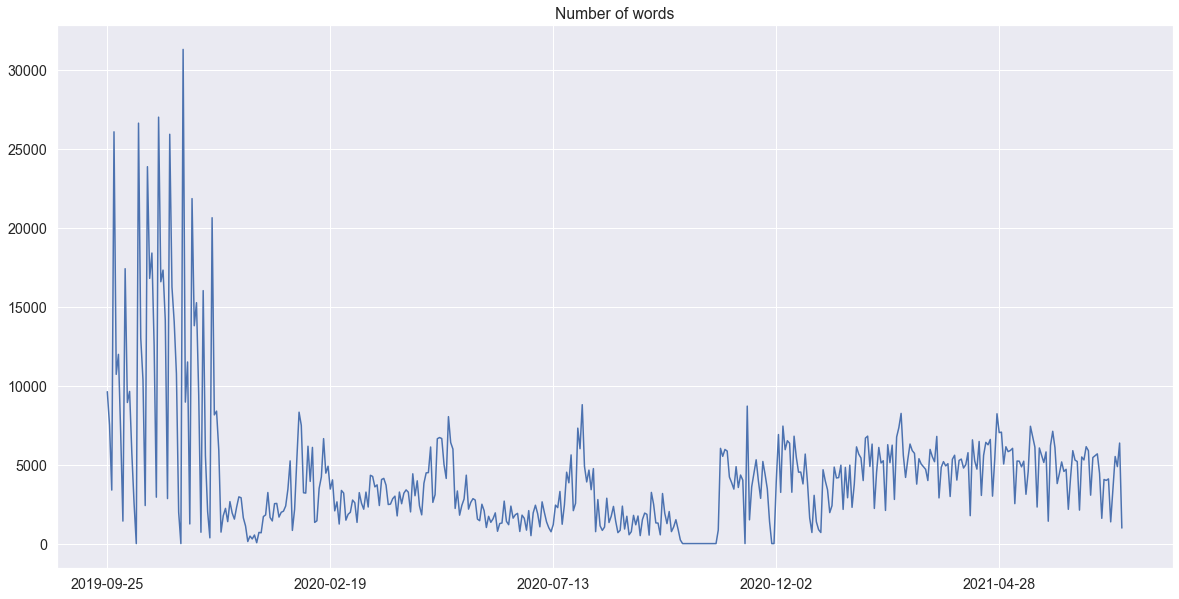

In [12]:
df['Num_word'].plot(figsize=(20, 10),title='Number of words')

In [13]:
plt.figure(figsize=(12,6))
p1=sns.kdeplot(df['Num_word'], shade=True, color="r").set_title('Kernel Distribution of Number Of words')
# p1=sns.kdeplot(train['Num_word_text'], shade=True, color="b")

KeyError: 'Num_words'

<Figure size 864x432 with 0 Axes>